In [21]:
import pickle
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.ticker import PercentFormatter


## Figure 2A–B: Node visitation

### mice

In [2]:

MICE = ["B4", "B5"]
BOUT_FRACTION = 1.0
N_NODES = 127

MOUSE_BASE_DIR = (
    Path("runs")
    / "runs_20_window"
    / "water_sparsity_0.1_hdim_64_zdim_16_beta1e-3_lr1e-3_1e-3_1e-3"
)

FIG_DIR = Path("paper_figures") / "mice_visitation_maps"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def load_mouse_visitation(mouse, bout_fraction=0.20):
    run_dir = MOUSE_BASE_DIR / mouse
    files = []

    for path in run_dir.glob("bout_*_metrics.npz"):
        match = re.fullmatch(r"bout_(\d+)_metrics\.npz", path.name)
        if match:
            files.append((int(match.group(1)), path))

    files.sort(key=lambda x: x[0])

    if not files:
        raise ValueError(f"No bout files in {run_dir}")

    n_total = len(files)
    n_selected = max(1, int(np.ceil(n_total * bout_fraction)))
    selected_files = files[-n_selected:]

    counts = np.zeros(N_NODES, dtype=np.int64)

    for bout_id, path in selected_files:
        with np.load(path, allow_pickle=True) as data:
            nodes = np.asarray(
                data["target_node"], dtype=int
            ).reshape(-1)

        if np.any((nodes < 0) | (nodes >= N_NODES)):
            raise ValueError(f"Invalid node IDs in {path}")

        counts += np.bincount(nodes, minlength=N_NODES)

    if counts.sum() == 0:
        raise ValueError(f"No transitions for {mouse}")

    probabilities = counts / counts.sum()

    print(
        f"{mouse}: {n_selected}/{n_total} bouts | "
        f"{counts.sum()} transitions | "
        f"{np.count_nonzero(counts)} visited nodes"
    )

    return probabilities, counts


visitation_maps = {}
visitation_counts = {}

for mouse in MICE:
    probs, counts = load_mouse_visitation(mouse, BOUT_FRACTION)
    visitation_maps[mouse] = probs
    visitation_counts[mouse] = counts

pd.DataFrame({
    "node": np.arange(N_NODES),
    "B4_probability": visitation_maps["B4"],
    "B5_probability": visitation_maps["B5"],
    "B4_count": visitation_counts["B4"],
    "B5_count": visitation_counts["B5"],
}).to_csv(
    FIG_DIR / "mice_visitation_probabilities.csv",
    index=False
)

B4: 203/203 bouts | 17312 transitions | 127 visited nodes
B5: 183/183 bouts | 14762 transitions | 127 visited nodes


In [3]:

def compute_node_points_from_contents(content_path, min_points_per_node=1):
    node_points = {}

    with open(content_path, "rb") as f:
        content = pickle.load(f)

    num_bouts = len(content.ke)

    for bout_idx in range(num_bouts):
        ke_bout = np.asarray(content.ke[bout_idx])
        no_bout = np.asarray(content.no[bout_idx])

        if ke_bout.size == 0 or no_bout.size == 0:
            continue

        T = ke_bout.shape[0]
        node_per_frame = np.full(T, np.nan)

        for i, (node_id, start_frame) in enumerate(no_bout):
            start = int(start_frame)
            end = int(no_bout[i + 1, 1]) if i + 1 < len(no_bout) else T

            start = max(0, min(start, T))
            end = max(start, min(end, T))

            node_per_frame[start:end] = int(node_id)

        valid = ~np.isnan(node_per_frame)

        if not np.any(valid):
            continue

        xs = ke_bout[valid, 0]
        ys = ke_bout[valid, 1]
        ns = node_per_frame[valid].astype(int)

        for x, y, n in zip(xs, ys, ns):
            d = node_points.setdefault(
                int(n),
                {"x": [], "y": [], "count": 0}
            )
            d["x"].append(float(x))
            d["y"].append(float(y))
            d["count"] += 1

    node_points = {
        n: d for n, d in node_points.items()
        if d["count"] >= min_points_per_node
    }

    return node_points


node_points = compute_node_points_from_contents(
    Path("outdata/A1a-tf")
)


In [4]:
for mouse in MICE:
    visited = set(np.flatnonzero(visitation_maps[mouse]))
    available = set(node_points)

    missing = sorted(visited - available)

    print(
        f"{mouse}: {len(missing)} visited nodes "
        f"missing from reference geometry"
    )

    if missing:
        print("Missing node IDs:", missing)

B4: 0 visited nodes missing from reference geometry
B5: 0 visited nodes missing from reference geometry


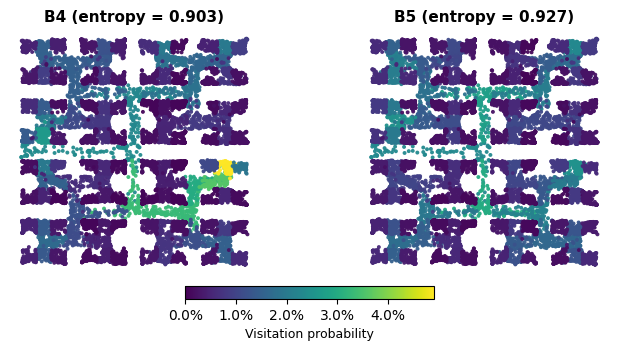

In [5]:

rng = np.random.default_rng(42)

MAX_POINTS_PER_NODE = 150

xy_parts = []
node_id_parts = []

for node_id, pts in sorted(node_points.items()):
    if not (0 <= node_id < N_NODES):
        continue

    xs = np.asarray(pts["x"])
    ys = np.asarray(pts["y"])

    if len(xs) == 0:
        continue

    n = min(len(xs), MAX_POINTS_PER_NODE)
    idx = rng.choice(len(xs), size=n, replace=False)

    xy_parts.append(
        np.column_stack([xs[idx], ys[idx]])
    )
    node_id_parts.append(
        np.full(n, node_id, dtype=int)
    )

xy = np.concatenate(xy_parts, axis=0)
node_ids = np.concatenate(node_id_parts)

max_prob = max(
    visitation_maps[mouse].max()
    for mouse in MICE
)

norm = Normalize(vmin=0, vmax=max_prob)
cmap = "viridis"

fig, axes = plt.subplots(
    1, 2,
    figsize=(7.0, 3.4),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

for ax, mouse in zip(axes, MICE):
    probs = visitation_maps[mouse]

    ax.scatter(
        xy[:, 0],
        xy[:, 1],
        c=probs[node_ids],
        cmap=cmap,
        norm=norm,
        s=8,
        alpha=0.95,
        linewidths=0,
        rasterized=True
    )

    p = probs[probs > 0]
    entropy = -np.sum(p * np.log(p))
    entropy_normalized = entropy / np.log(N_NODES)

    ax.set_title(
        f"{mouse} (entropy = {entropy_normalized:.3f})",
        fontsize=11,
        fontweight="bold",
        pad=4
    )

    ax.set_aspect("equal", adjustable="box")
    ax.set_axis_off()

axes[0].invert_yaxis()

sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=axes,
    orientation="horizontal",
    shrink=0.65,
    pad=0.04,
    fraction=0.05
)

cbar.set_label("Visitation probability", fontsize=9)
cbar.ax.xaxis.set_major_formatter(
    PercentFormatter(xmax=1.0, decimals=1)
)

for ext in ["svg", "pdf", "png"]:
    fig.savefig(
        FIG_DIR / f"mice_visitation.{ext}",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close(fig)


### Simulated agents

In [6]:

ROOT = Path.cwd()

AGENT_BASE_DIR = (
    ROOT / "runs" / "REWARD_DRIVEN_1000"
)

AGENT_WINDOW = (0.8, 1.0)
N_NODES = 127

FIG_DIR = ROOT / "paper_figures" / "agent_visitation_maps"
FIG_DIR.mkdir(parents=True, exist_ok=True)


In [7]:

PANEL_SPECS = [
    {"p": 0.0, "seed": 0},
    {"p": 0.05, "seed": 0},
    {"p": 0.1, "seed": 0},
    {"p": 0.1, "seed": 1},
]


def get_agent_run_dir(p, seed):
    return (
        AGENT_BASE_DIR
        / f"REWARD_DRIVEN_1000_runs_slurm_20_window_agent_rew_p_{p}"
        / str(seed)
    )


In [8]:

def load_agent_visitation(p, seed, window=(0.8, 1.0)):
    run_dir = get_agent_run_dir(p, seed)
    files = []

    for path in run_dir.glob("bout_*_metrics.npz"):
        match = re.fullmatch(r"bout_(\d+)_metrics\.npz", path.name)
        if match:
            files.append((int(match.group(1)), path))

    files.sort(key=lambda x: x[0])

    if not files:
        raise ValueError(f"No bout files in {run_dir}")

    n_total = len(files)
    start = int(round(window[0] * n_total))
    end = int(round(window[1] * n_total))

    selected_files = files[start:end]
    counts = np.zeros(N_NODES, dtype=np.int64)

    for bout_id, path in selected_files:
        with np.load(path, allow_pickle=False) as data:
            nodes = np.asarray(
                data["target_node"], dtype=int
            ).reshape(-1)

        if np.any((nodes < 0) | (nodes >= N_NODES)):
            raise ValueError(f"Invalid node IDs in {path}")

        counts += np.bincount(nodes, minlength=N_NODES)

    if counts.sum() == 0:
        raise ValueError(f"No transitions for p={p}, seed={seed}")

    probs = counts / counts.sum()

    nz = probs[probs > 0]
    entropy = -np.sum(nz * np.log(nz))
    entropy_normalized = entropy / np.log(N_NODES)

    print(
        f"p={p:g}, seed={seed}: "
        f"{len(selected_files)}/{n_total} bouts | "
        f"{counts.sum()} transitions | "
        f"{np.count_nonzero(counts)} visited nodes | "
        f"entropy={entropy_normalized:.3f}"
    )

    return probs, counts, entropy_normalized


agent_visitation = {}

for spec in PANEL_SPECS:
    key = (spec["p"], spec["seed"])

    probs, counts, entropy = load_agent_visitation(
        p=spec["p"],
        seed=spec["seed"],
        window=AGENT_WINDOW
    )

    agent_visitation[key] = {
        "probabilities": probs,
        "counts": counts,
        "entropy": entropy,
    }


p=0, seed=0: 200/1000 bouts | 13754 transitions | 127 visited nodes | entropy=0.947
p=0.05, seed=0: 200/1000 bouts | 13591 transitions | 127 visited nodes | entropy=0.772
p=0.1, seed=0: 200/1000 bouts | 13804 transitions | 123 visited nodes | entropy=0.624
p=0.1, seed=1: 200/1000 bouts | 13716 transitions | 126 visited nodes | entropy=0.579


In [9]:
print("Physical maze coordinates:", xy.shape)
print("Nodes represented:", len(np.unique(node_ids)))

Physical maze coordinates loaded!
xy shape: (18960, 2)
node_ids shape: (18960,)
Nodes represented: 127


In [ ]:

n_panels = len(PANEL_SPECS)
ncols = 4
nrows = int(np.ceil(n_panels / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(3.2 * ncols, 3.7 * nrows),
    sharex=True,
    sharey=True,
    squeeze=False
)

axes = axes.flatten()

for ax, spec in zip(axes, PANEL_SPECS):
    p = spec["p"]
    seed = spec["seed"]
    key = (p, seed)

    probs = agent_visitation[key]["probabilities"]
    entropy = agent_visitation[key]["entropy"]

    norm = Normalize(vmin=0, vmax=probs.max())
    cmap = "viridis"

    sc = ax.scatter(
        xy[:, 0],
        xy[:, 1],
        c=probs[node_ids],
        cmap=cmap,
        norm=norm,
        s=8,
        alpha=0.95,
        linewidths=0,
        rasterized=True
    )

    ax.set_title(
        rf"$p={p:g}$, seed={seed}" + "\n" +
        rf"entropy = {entropy:.3f}",
        fontsize=10,
        fontweight="bold",
        pad=4
    )

    ax.set_aspect("equal", adjustable="box")
    ax.set_axis_off()

    cbar = fig.colorbar(
        sc,
        ax=ax,
        orientation="horizontal",
        fraction=0.05,
        pad=0.03
    )

    cbar.set_label("Visitation probability", fontsize=8)
    cbar.ax.tick_params(labelsize=7)
    cbar.ax.xaxis.set_major_formatter(
        PercentFormatter(xmax=1.0, decimals=1)
    )

for ax in axes[n_panels:]:
    ax.set_visible(False)

axes[0].invert_yaxis()

fig.tight_layout()

fig.savefig(
    FIG_DIR / "agent_visitation_individual_colorbars.svg",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

## Figure 2C–E: Behavioral and predictive performance

In [16]:

METRICS_DIR = ROOT / "maze_metric_outputs_basic"
FIG_DIR = ROOT / "paper_figures" / "figure_2"
FIG_DIR.mkdir(parents=True, exist_ok=True)

WINDOW = (0.9, 1.0)
SEEDS = [str(i) for i in range(15)]

COLORS = {
    "reward": "#18545D",
    "entropy": "#A6533D",
    "ce": "#18545D",
    "consistency": "#A6533D",
    "success": "#18545D",
    "steps": "#A6533D",
    "ink": "#30363A",
    "grid": "#DFE7E5",
    "left_text": "#18545D",
    "right_text": "#A6533D",
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9.5,
    "axes.labelsize": 9.5,
    "axes.titlesize": 10,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.fontsize": 8,
    "axes.linewidth": 0.8,
    "axes.edgecolor": COLORS["ink"],
    "text.color": COLORS["ink"],
    "xtick.color": COLORS["ink"],
    "lines.linewidth": 2.0,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "savefig.transparent": False,
})


def select_window(df):
    return df[
        np.isclose(df["window_start"], WINDOW[0])
        & np.isclose(df["window_end"], WINDOW[1])
    ].copy()


summary = select_window(
    pd.read_csv(METRICS_DIR / "summary.csv", dtype={"seed": str})
)

behavior = select_window(
    pd.read_csv(METRICS_DIR / "behavior_metrics.csv", dtype={"seed": str})
)

summary = summary[summary["seed"].isin(SEEDS)].copy()
behavior = behavior[behavior["seed"].isin(SEEDS)].copy()

print("Summary seeds:", summary["seed"].nunique())
print("Behavior seeds:", behavior["seed"].nunique())
print("Summary rows:", len(summary))
print("Behavior rows:", len(behavior))
print("Number of p values:", summary["p"].nunique())


Summary seeds: 15
Behavior seeds: 15
Summary rows: 180
Behavior rows: 180
Number of p values: 12


In [17]:

def mean_sem(df, metric):
    stats = (
        df.groupby("p")[metric]
        .agg(["mean", "std", "count"])
        .reset_index()
        .sort_values("p")
    )

    stats["sem"] = stats["std"] / np.sqrt(stats["count"])
    return stats


def add_curve(ax, df, metric, color, label, marker="o"):
    stats = mean_sem(df, metric)

    return ax.errorbar(
        stats["p"],
        stats["mean"],
        yerr=stats["sem"].fillna(0),
        color=color,
        marker=marker,
        markersize=4.5,
        markeredgecolor="white",
        markeredgewidth=0.5,
        linewidth=2.0,
        elinewidth=0.9,
        capsize=2.0,
        capthick=0.9,
        label=label,
        zorder=3
    )


def style_axis(ax):
    ax.set_xlabel(r"Reward-driven switching probability $p$")
    ax.set_xlim(-0.004, 0.104)
    ax.set_xticks(np.arange(0, 0.101, 0.02))

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(
        axis="y",
        color=COLORS["grid"],
        linewidth=0.7
    )

    ax.set_axisbelow(True)
    ax.tick_params(direction="out", length=3, width=0.8)


def style_twin(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.tick_params(direction="out", length=3, width=0.8)


def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.svg", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    print("Saved:", name)


def legend_two(ax, h1, h2):
    ax.legend(
        [h1, h2],
        [h1.get_label(), h2.get_label()],
        loc="lower center",
        bbox_to_anchor=(0.5, 1.01),
        ncol=2,
        frameon=False,
        fontsize=7.2,
        handlelength=1.5,
        columnspacing=1.0
    )


Saved: fig2c_exploration


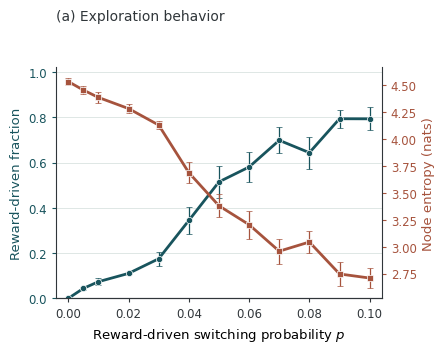

In [18]:

def plot_fig2c(ax):
    style_axis(ax)

    ax2 = ax.twinx()
    style_twin(ax2)

    h1 = add_curve(
        ax, behavior,
        "reward_driven_fraction",
        COLORS["left_text"],
        "Reward-driven actions"
    )

    h2 = add_curve(
        ax2, behavior,
        "node_entropy",
        COLORS["right_text"],
        "Node entropy",
        marker="s"
    )

    ax.set_ylabel(
        "Reward-driven fraction",
        color=COLORS["left_text"]
    )
    ax2.set_ylabel(
        "Node entropy (nats)",
        color=COLORS["right_text"]
    )

    ax.tick_params(axis="y", colors=COLORS["left_text"])
    ax2.tick_params(axis="y", colors=COLORS["right_text"])

    ax.set_ylim(0, 1.02)
    ax.set_title("(a) Exploration behavior", loc="left", pad=34)


fig, ax = plt.subplots(figsize=(4.2, 3.0))
plot_fig2c(ax)

save_fig(fig, "fig2c_exploration")
plt.show()
plt.close(fig)


Saved: fig2d_transition_ce_coverage


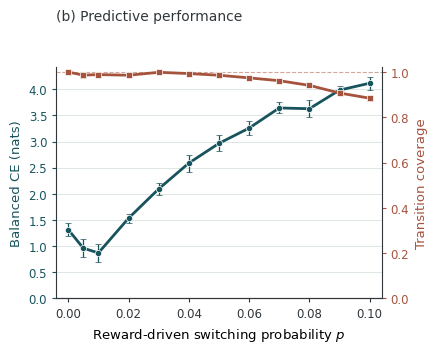

In [19]:

def plot_fig2d(ax):
    style_axis(ax)

    ax2 = ax.twinx()
    style_twin(ax2)

    h1 = add_curve(
        ax, summary,
        "transition_balanced_ce",
        COLORS["ce"],
        "Transition-balanced CE",
        marker="o"
    )

    h2 = add_curve(
        ax2, summary,
        "transition_coverage",
        COLORS["consistency"],
        "Transition coverage",
        marker="s"
    )

    ax.set_ylabel(
        "Balanced CE (nats)",
        color=COLORS["ce"]
    )
    ax2.set_ylabel(
        "Transition coverage",
        color=COLORS["right_text"]
    )

    ax.tick_params(axis="y", colors=COLORS["ce"])
    ax2.tick_params(axis="y", colors=COLORS["right_text"])

    ax.set_ylim(bottom=0)
    ax2.set_ylim(0, 1.02)

    ax2.axhline(
        1.0,
        color=COLORS["consistency"],
        linestyle="--",
        linewidth=0.8,
        alpha=0.5
    )

    ax.set_title(
        "(b) Predictive performance",
        loc="left",
        pad=34
    )


fig, ax = plt.subplots(figsize=(4.2, 3.0))
plot_fig2d(ax)

save_fig(fig, "fig2d_transition_ce_coverage")
plt.show()
plt.close(fig)


Saved: fig2e_reward_performance


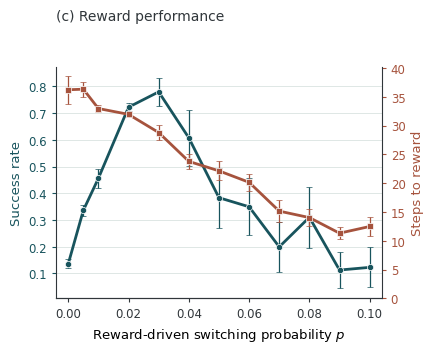

In [20]:

def plot_fig2e(ax):
    style_axis(ax)

    ax2 = ax.twinx()
    style_twin(ax2)

    h1 = add_curve(
        ax, summary,
        "success_rate",
        COLORS["success"],
        "Success rate"
    )

    h2 = add_curve(
        ax2, summary,
        "steps_success",
        COLORS["steps"],
        "Steps to reward",
        marker="s"
    )

    ax.set_ylabel(
        "Success rate",
        color=COLORS["success"]
    )
    ax2.set_ylabel(
        "Steps to reward",
        color=COLORS["right_text"]
    )

    ax.tick_params(axis="y", colors=COLORS["success"])
    ax2.tick_params(axis="y", colors=COLORS["right_text"])

    ax2.set_ylim(bottom=0)
    ax.set_title("(c) Reward performance", loc="left", pad=34)


fig, ax = plt.subplots(figsize=(4.2, 3.0))
plot_fig2e(ax)

save_fig(fig, "fig2e_reward_performance")
plt.show()
plt.close(fig)
